In [40]:
import torch
import cv2
import matplotlib.pyplot as plt

In [21]:
# Load the image using OpenCV
image = cv2.imread("../data/raw/drone_sample.jpg")

# Convert the image from BGR to RGB 
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [22]:
# Convert the UAV image from a NumPy array to a PyTorch tensor
tensor_image = torch.from_numpy(rgb_image)

# Check the dimensions of the image tensor
tensor_image.shape

torch.Size([765, 1360, 3])

In [23]:
# Rearrange the image tensor dimensions from HWC to CHW
converted_tensor = tensor_image.permute(2, 0, 1)

# Check the dimensions of the converted tensor
converted_tensor.shape

torch.Size([3, 765, 1360])

In [24]:
# Convert the image tensor to float32 and normalize pixel values to [0, 1]
normalized_tensor = converted_tensor.float() / 255.0

In [26]:
# Add a batch dimension to represent a single UAV image
batch_tensor = normalized_tensor.unsqueeze(0)

# Check the dimensions of the batched image tensor
batch_tensor.shape

torch.Size([1, 3, 765, 1360])

In [38]:
# Extract the first UAV image from the batch
single_image = batch_tensor[0]

# Extract the Red channel from the RGB image tensor
red_channel = single_image[0]

# Check the dimensions of the Red channel
red_channel.shape

torch.Size([765, 1360])

In [41]:
# Calculate basic pixel statistics of the normalized UAV image
print(single_image.min())
print(single_image.max())
print(single_image.mean())
print(single_image.std())

tensor(0.)
tensor(1.)
tensor(0.2173)
tensor(0.1177)


In [60]:
# Increase the brightness of the UAV image
bright_image = single_image + 0.2

# Keep pixel values within the valid range [0, 1]
bright_image = torch.clamp(bright_image, min = 0, max = 1)

# Rearrange tensor dimensions from CHW to HWC for visualization
bright_image_hwc = bright_image.permute(1, 2, 0)

# Check the dimensions of the brightened image
bright_image_hwc.shape

torch.Size([765, 1360, 3])

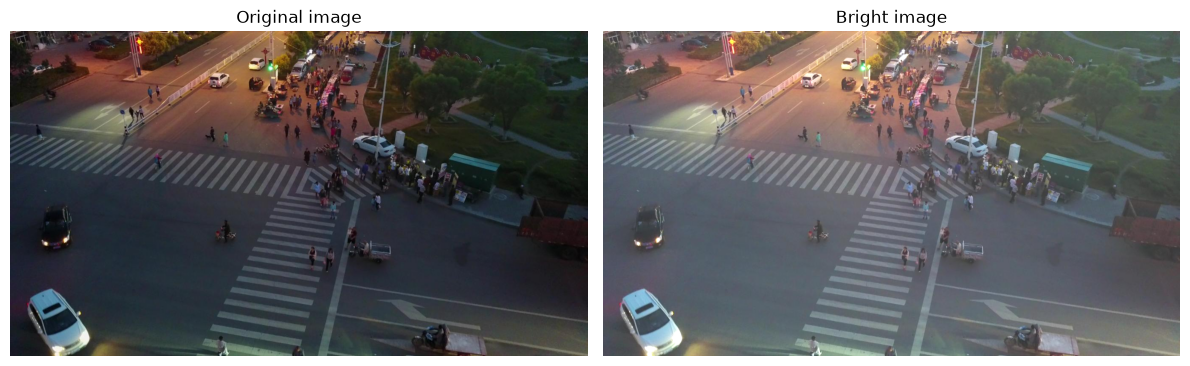

In [63]:
# Compare the original and brightness-adjusted UAV images
fig, axes = plt.subplots(1, 2, figsize = (12, 5))

# Display the original RGB image
axes[0].imshow(rgb_image)
axes[0].axis("off")
axes[0].set_title("Original image")

# Display the brightness-adjusted image
axes[1].imshow(bright_image_hwc)
axes[1].axis("off")
axes[1].set_title("Bright image")

# Adjust subplot spacing and display the comparison
plt.tight_layout()
plt.show()

In [80]:
# Create a tensor with gradient tracking enabled
w = torch.tensor(1.0, requires_grad = True)

# Calculate the loss
loss = (w - 3) ** 2

# Compute the gradient using automatic differentiation
loss.backward()

# Display the calculated gradient
print(w.grad)

tensor(-4.)


In [81]:
# Define the learning rate
learning_rate = 0.1

# Update the parameter without tracking gradients
with torch.no_grad():
    w -= learning_rate * w.grad

# Calculate the new loss
loss_new = (w - 3) ** 2

# Display the updated parameter and loss
print("Updated weight:", w.item())
print("New loss:", loss_new.item())

Updated weight: 1.399999976158142
New loss: 2.56000018119812
